# Tomato Plant Disease Classification — Updated CNN Notebook

A reproducible CPU-only CNN baseline using TensorFlow/Keras.

**Consistent input size throughout this notebook:** 160 × 160 RGB (`(160, 160, 3)`).

Expected dataset structure:
`dataset/train/class_name/...` and `dataset/valid/class_name/...`

**Research caution:** validation data is not an independent test set. Check that augmented versions of the same original image have not leaked across splits.

## 1. Install dependencies (only if needed)

In [1]:
# Run only if packages are missing; restart the kernel after installation if required.
%pip install --upgrade tensorflow scikit-learn matplotlib seaborn pandas pillow

^C
Note: you may need to restart the kernel to use updated packages.


## 2. Configure CPU-only execution
Run this before TensorFlow initializes. Restart the kernel if TensorFlow was already imported.

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import tensorflow as tf

try:
    tf.config.set_visible_devices([], "GPU")
except RuntimeError:
    print("Devices already initialized; restart kernel to apply CPU-only settings.")

try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print("Thread settings already initialized; continuing.")

print("TensorFlow:", tf.__version__)
print("CPU:", tf.config.list_physical_devices("CPU"))
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPU: []


## 3. Imports and reproducibility

In [3]:
from pathlib import Path
import json
import hashlib
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError

from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 4. Dataset paths and experiment settings
**Edit `DATASET_DIR`** to match the actual folder on your computer.

In [4]:
DATASET_DIR = Path(r"D:\NN\Tomato Plant Diseases Augmented\dataset")

TRAIN_DIR = DATASET_DIR / "train"
VALID_DIR = DATASET_DIR / "valid"

# Use these dimensions consistently in loading, augmentation, and model input.
IMG_SIZE = (160, 160)
INPUT_SHAPE = (160, 160, 3)

BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 1e-3

OUTPUT_DIR = Path("tomato_cnn_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_DIR.resolve())
print("Train folder exists:", TRAIN_DIR.exists())
print("Valid folder exists:", VALID_DIR.exists())
print("IMG_SIZE:", IMG_SIZE)

Dataset: D:\NN\Tomato Plant Diseases Augmented\Dataset
Train folder exists: True
Valid folder exists: True
IMG_SIZE: (160, 160)


## 5. Validate folders and discover classes

In [5]:
if not TRAIN_DIR.exists():
    raise FileNotFoundError(f"Training folder not found: {TRAIN_DIR}")
if not VALID_DIR.exists():
    raise FileNotFoundError(f"Validation folder not found: {VALID_DIR}")

train_classes = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
valid_classes = sorted(p.name for p in VALID_DIR.iterdir() if p.is_dir())

if not train_classes:
    raise ValueError("No class folders found in the training directory.")
if train_classes != valid_classes:
    raise ValueError(f"Train/validation class folders differ: {train_classes} vs {valid_classes}")

CLASS_NAMES = train_classes
NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
for i, name in enumerate(CLASS_NAMES):
    print(i, name)

Number of classes: 10
0 Tomato___Bacterial_spot
1 Tomato___Early_blight
2 Tomato___Late_blight
3 Tomato___Leaf_Mold
4 Tomato___Septoria_leaf_spot
5 Tomato___Spider_mites Two-spotted_spider_mite
6 Tomato___Target_Spot
7 Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 Tomato___Tomato_mosaic_virus
9 Tomato___healthy


## 6. Count images by class

,class_name,train_images,valid_images
0,Tomato___Bacterial_spot,1702,425
1,Tomato___Early_blight,1920,480
2,Tomato___Late_blight,1851,463
3,Tomato___Leaf_Mold,1882,470
4,Tomato___Septoria_leaf_spot,1745,436
5,Tomato___Spider_mites Two-spotted_spider_mite,1741,435
6,Tomato___Target_Spot,1827,457
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,1961,490
8,Tomato___Tomato_mosaic_virus,1790,448
9,Tomato___healthy,1926,481


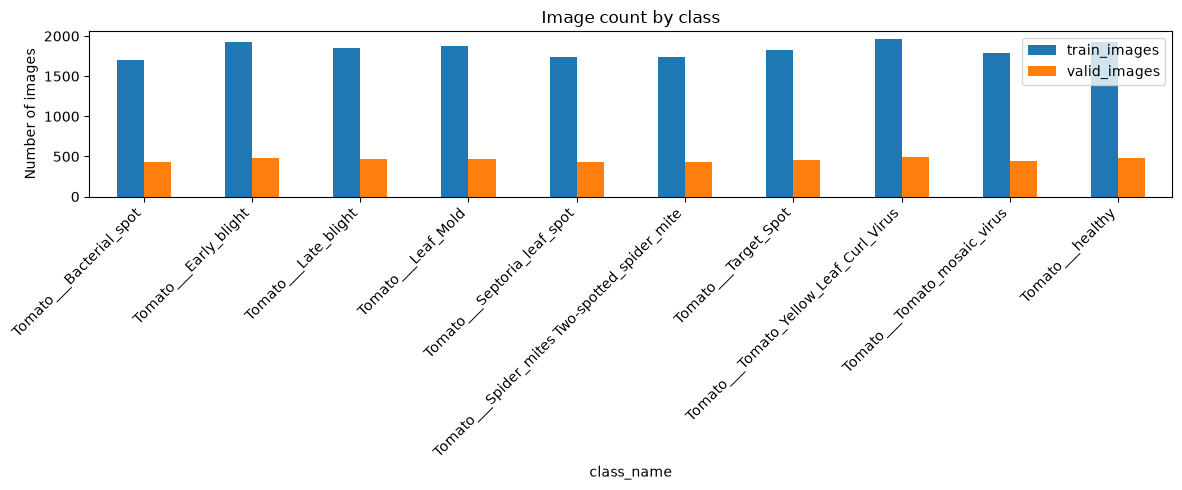

Training total: 18345
Validation total: 4585


In [6]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def count_images_by_class(folder):
    return {
        p.name: sum(
            1 for f in p.rglob("*")
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        )
        for p in sorted(folder.iterdir()) if p.is_dir()
    }

train_counts = count_images_by_class(TRAIN_DIR)
valid_counts = count_images_by_class(VALID_DIR)

distribution_df = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "train_images": [train_counts[c] for c in CLASS_NAMES],
    "valid_images": [valid_counts[c] for c in CLASS_NAMES]
})
display(distribution_df)

distribution_df.set_index("class_name").plot(
    kind="bar", figsize=(12, 5), title="Image count by class"
)
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Training total:", sum(train_counts.values()))
print("Validation total:", sum(valid_counts.values()))

## 7. Check for corrupt images

In [7]:
def find_corrupt_images(folder):
    corrupt = []
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            try:
                with Image.open(path) as img:
                    img.verify()
            except (UnidentifiedImageError, OSError, ValueError):
                corrupt.append(str(path))
    return corrupt

corrupt_train = find_corrupt_images(TRAIN_DIR)
corrupt_valid = find_corrupt_images(VALID_DIR)

print("Corrupt training images:", len(corrupt_train))
print("Corrupt validation images:", len(corrupt_valid))
for path in (corrupt_train + corrupt_valid)[:20]:
    print(path)

Corrupt training images: 0
Corrupt validation images: 0


## 8. Detect exact duplicates across train and validation
SHA-256 detects byte-identical files only; it does not detect transformed or augmented derivatives.

In [8]:
def collect_hashes(folder):
    result = {}
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            try:
                digest = hashlib.sha256(path.read_bytes()).hexdigest()
                result.setdefault(digest, []).append(str(path))
            except OSError:
                pass
    return result

train_hashes = collect_hashes(TRAIN_DIR)
valid_hashes = collect_hashes(VALID_DIR)
duplicate_hashes = set(train_hashes) & set(valid_hashes)

print("Exact duplicate contents across splits:", len(duplicate_hashes))
for digest in list(duplicate_hashes)[:10]:
    print("\n", digest)
    print("Train:", train_hashes[digest][:2])
    print("Valid:", valid_hashes[digest][:2])

Exact duplicate contents across splits: 4

 4913a3835e692530e507d542caccacc0d0a7b2fd708782cdec6236a1a0dbbcd6
Train: ['D:\\NN\\Tomato Plant Diseases Augmented\\dataset\\train\\Tomato___Late_blight\\5de6da85-f8c4-48c4-b463-3e6bd78884cc___GHLB_PS Leaf 24 Day 16.jpg']
Valid: ['D:\\NN\\Tomato Plant Diseases Augmented\\dataset\\valid\\Tomato___Late_blight\\3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg']

 a05e573ae6c4a28b077b8c9d01249be849f4f8e1790b2625b42c6bc01098f718
Train: ['D:\\NN\\Tomato Plant Diseases Augmented\\dataset\\train\\Tomato___Late_blight\\d81682aa-746b-4e07-af2b-52ebb6f4c017___GHLB2 Leaf 102.JPG']
Valid: ['D:\\NN\\Tomato Plant Diseases Augmented\\dataset\\valid\\Tomato___Late_blight\\d6e6897a-5083-4914-9903-804c5684a956___GHLB2 Leaf 102.JPG']

 68cda8c3ceca7626cc6727e14186d356b10d1e345eb16e425ef82f21a30258ed
Train: ['D:\\NN\\Tomato Plant Diseases Augmented\\dataset\\train\\Tomato___healthy\\37aad83b-7ff8-4b35-b3ed-fb8e0f54910b___GH_HL Leaf 342.1.JPG']
Val

## 9. Load datasets at 160 × 160
Both datasets must yield image batches shaped `(batch, 160, 160, 3)`.

In [9]:
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

valid_ds = keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

assert train_ds.class_names == CLASS_NAMES
assert valid_ds.class_names == CLASS_NAMES
print("Class order:", train_ds.class_names)

Found 18345 files belonging to 10 classes.
Found 4585 files belonging to 10 classes.
Class order: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


## 10. Verify tensor shapes and pixel range

In [10]:
for images, labels in train_ds.take(1):
    print("Images:", images.shape)
    print("Labels:", labels.shape)
    print("Dtype:", images.dtype)
    print("Pixel range:", tf.reduce_min(images).numpy(), "to", tf.reduce_max(images).numpy())

assert tuple(train_ds.element_spec[0].shape[1:]) == INPUT_SHAPE
assert tuple(valid_ds.element_spec[0].shape[1:]) == INPUT_SHAPE

Images: (16, 160, 160, 3)
Labels: (16,)
Dtype: <dtype: 'float32'>
Pixel range: 0.0 to 251.33035


## 11. Display sample images

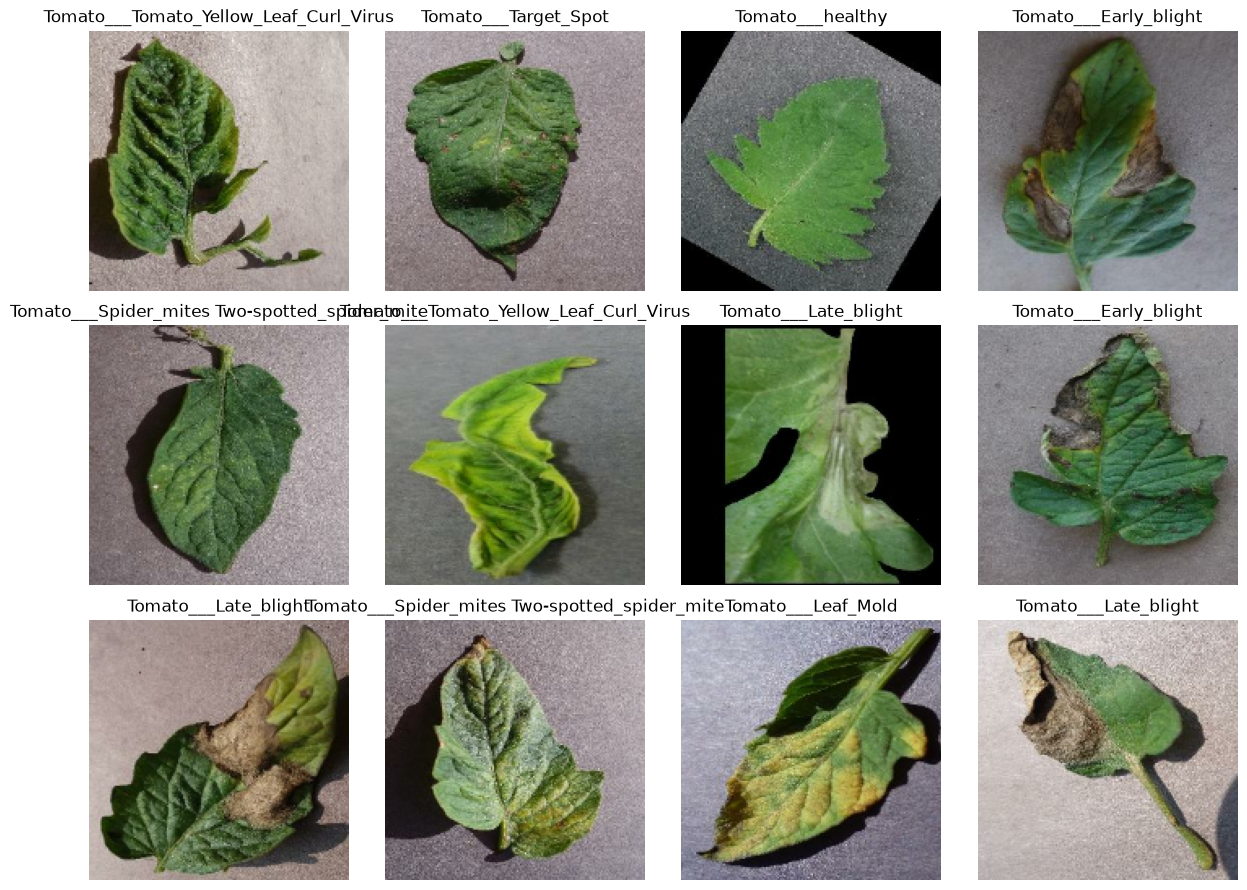

In [11]:
plt.figure(figsize=(12, 9))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[int(labels[i].numpy())])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 12. Prefetch datasets

In [12]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)

## 13. Data augmentation
This layer intentionally has no hard-coded 224 × 224 input shape. It accepts the incoming 160 × 160 image tensors.

In [13]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ],
    name="data_augmentation"
)

## 14. Define the organized CNN architecture

In [15]:
def build_cnn(num_classes, input_shape=(160, 160, 3)):
    # Input image
    inputs = keras.Input(shape=input_shape, name="input_image")

    # Augmentation and normalization
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255, name="normalization")(x)

    # Convolutional block 1
    x = layers.Conv2D(32, (3, 3), padding="same",
                      activation="relu", name="conv_block_1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool_1")(x)

    # Convolutional block 2
    x = layers.Conv2D(64, (3, 3), padding="same",
                      activation="relu", name="conv_block_2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool_2")(x)

    # Convolutional block 3
    x = layers.Conv2D(128, (3, 3), padding="same",
                      activation="relu", name="last_conv")(x)
    x = layers.MaxPooling2D((2, 2), name="pool_3")(x)

    # Feature aggregation
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)

    # Classification head
    x = layers.Dense(128, activation="relu",
                     name="classification_dense")(x)
    x = layers.Dropout(0.4, name="dropout")(x)

    # Class probabilities
    outputs = layers.Dense(num_classes, activation="softmax",
                           name="predictions")(x)

    return keras.Model(inputs, outputs, name="Tomato_Disease_CNN")

## 15. Build model and run shape checks
Do not proceed unless all printed image dimensions agree.

In [16]:
model = build_cnn(
    num_classes=NUM_CLASSES,
    input_shape=INPUT_SHAPE
)

print("Training batch shape:", train_ds.element_spec[0].shape)
print("Validation batch shape:", valid_ds.element_spec[0].shape)
print("Model input shape:", model.input_shape)
print("Augmentation input shape:", data_augmentation.input_shape)

assert tuple(model.input_shape[1:]) == INPUT_SHAPE
assert tuple(train_ds.element_spec[0].shape[1:]) == INPUT_SHAPE
assert tuple(valid_ds.element_spec[0].shape[1:]) == INPUT_SHAPE

model.summary()

Training batch shape: (None, 160, 160, 3)
Validation batch shape: (None, 160, 160, 3)
Model input shape: (None, 160, 160, 3)
Augmentation input shape: (None, 160, 160, 3)


Model: "Tomato_Disease_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Rescaling)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_1 (Conv2D)           │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_2 (Conv2D)           │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_dense (Dense)    │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

## 16. Compile model

In [17]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

## 17. Configure callbacks

In [18]:
best_model_path = OUTPUT_DIR / "tomato_cnn_best.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

## 18. Train the CNN

In [19]:
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

training_seconds = time.time() - start_time
print(f"Training duration: {training_seconds / 60:.2f} minutes")

Epoch 1/20


C:\Users\Abo Sajid\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1147/1147 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.3634 - loss: 1.7056
Epoch 1: val_loss improved from None to 1.19959, saving model to tomato_cnn_outputs\tomato_cnn_best.keras

Epoch 1: finished saving model to tomato_cnn_outputs\tomato_cnn_best.keras
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 278s 240ms/step - accuracy: 0.3634 - loss: 1.7056 - val_accuracy: 0.5411 - val_loss: 1.1996 - learning_rate: 0.0010
Epoch 2/20
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.6003 - loss: 1.0998
Epoch 2: val_loss improved from 1.19959 to 0.70338, saving model to tomato_cnn_outputs\tomato_cnn_best.keras

Epoch 2: finished saving model to tomato_cnn_outputs\tomato_cnn_best.keras
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 277s 241ms/step - accuracy: 0.6003 - loss: 1.0998 - val_accuracy: 0.7529 - val_loss: 0.7034 - learning_rate: 0.0010
Epoch 3/20
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.7172 - loss: 0.7967
Epoch 3: val_loss improved from 0.70338 to 0.58055, saving model to tomato_cnn_o

1147/1147 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.7876 - loss: 0.6177
Epoch 4: val_loss improved from 0.58055 to 0.51436, saving model to tomato_cnn_outputs\tomato_cnn_best.keras

Epoch 4: finished saving model to tomato_cnn_outputs\tomato_cnn_best.keras
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 287s 250ms/step - accuracy: 0.7876 - loss: 0.6177 - val_accuracy: 0.8294 - val_loss: 0.5144 - learning_rate: 0.0010
Epoch 5/20
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.8072 - loss: 0.5508
Epoch 5: val_loss did not improve from 0.51436
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 269s 235ms/step - accuracy: 0.8072 - loss: 0.5508 - val_accuracy: 0.7967 - val_loss: 0.6147 - learning_rate: 0.0010
Epoch 6/20
1147/1147 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.8355 - loss: 0.4697
Epoch 6: val_loss improved from 0.51436 to 0.39668, saving model to tomato_cnn_outputs\tomato_cnn_best.keras

Epoch 6: finished saving model to tomato_cnn_outputs\tomato_cnn_best.keras
1147/1147 ━━━━━━━━━━━━━━━━━━━━

## 19. Plot accuracy

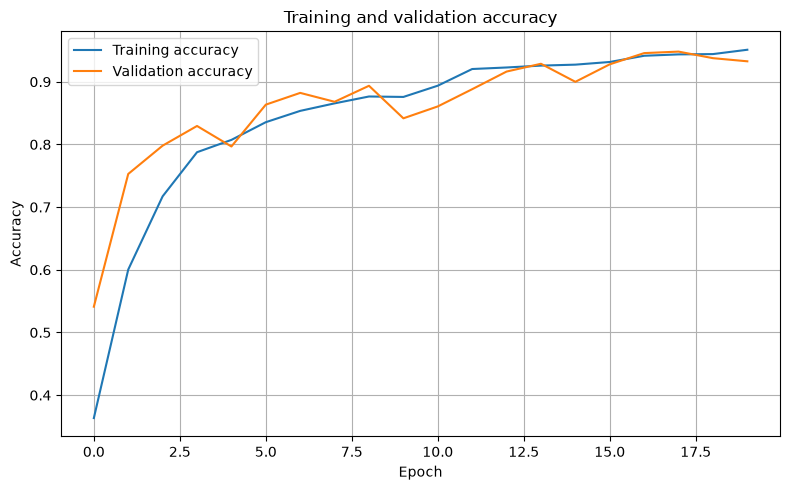

In [20]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 20. Plot loss

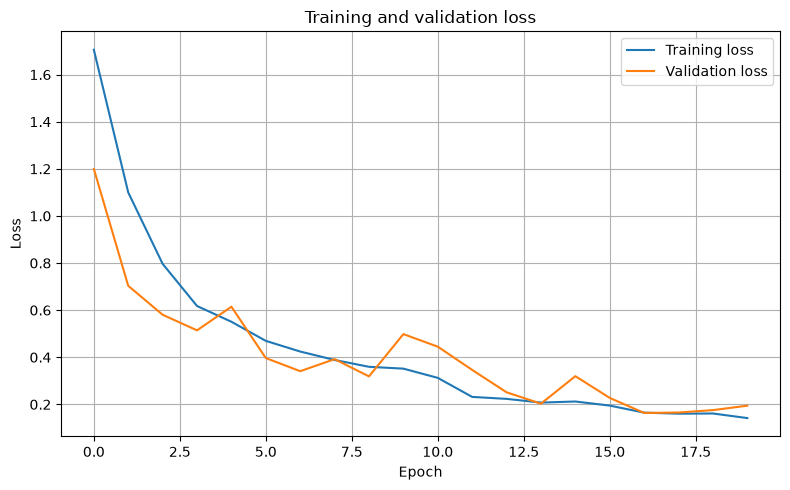

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 21. Load the best checkpoint

In [22]:
if best_model_path.exists():
    model = keras.models.load_model(best_model_path)
    print("Best checkpoint loaded:", best_model_path)
else:
    print("Checkpoint not found; using current model.")

Best checkpoint loaded: tomato_cnn_outputs\tomato_cnn_best.keras


## 22. Evaluate validation set

In [23]:
val_loss, val_accuracy = model.evaluate(valid_ds, verbose=1)
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")

287/287 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.9457 - loss: 0.1637
Validation loss: 0.1637
Validation accuracy: 0.9457


## 23. Generate predictions

In [24]:
y_true_parts = []
y_prob_parts = []

for images, labels in valid_ds:
    probabilities = model.predict(images, verbose=0)
    y_true_parts.append(labels.numpy())
    y_prob_parts.append(probabilities)

y_true = np.concatenate(y_true_parts)
y_prob = np.concatenate(y_prob_parts)
y_pred = np.argmax(y_prob, axis=1)

print("Validation examples:", len(y_true))
print("Probability matrix:", y_prob.shape)

Validation examples: 4585
Probability matrix: (4585, 10)


## 24. Classification report

In [25]:
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

report_dict = classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True
)
display(pd.DataFrame(report_dict).transpose().round(4))

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.97      0.90      0.94       425
                        Tomato___Early_blight       0.89      0.98      0.93       480
                         Tomato___Late_blight       0.96      0.90      0.93       463
                           Tomato___Leaf_Mold       0.95      0.98      0.97       470
                  Tomato___Septoria_leaf_spot       0.96      0.95      0.96       436
Tomato___Spider_mites Two-spotted_spider_mite       0.91      0.88      0.90       435
                         Tomato___Target_Spot       0.92      0.88      0.90       457
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.95      0.99      0.97       490
                 Tomato___Tomato_mosaic_virus       0.98      0.99      0.98       448
                             Tomato___healthy       0.97      0.99      0.98       481

                                     accu

,precision,recall,f1-score,support
Tomato___Bacterial_spot,0.9746,0.9012,0.9364,425.0000
Tomato___Early_blight,0.8899,0.9771,0.9315,480.0000
Tomato___Late_blight,0.9566,0.9050,0.9301,463.0000
Tomato___Leaf_Mold,0.9545,0.9809,0.9675,470.0000
Tomato___Septoria_leaf_spot,0.9607,0.9541,0.9574,436.0000
Tomato___Spider_mites Two-spotted_spider_mite,0.9143,0.8828,0.8982,435.0000
Tomato___Target_Spot,0.9217,0.8753,0.8979,457.0000
Tomato___Tomato_Yellow_Leaf_Curl_Virus,0.9452,0.9857,0.9650,490.0000
Tomato___Tomato_mosaic_virus,0.9759,0.9933,0.9845,448.0000
Tomato___healthy,0.9714,0.9896,0.9804,481.0000


## 25. Confusion matrix

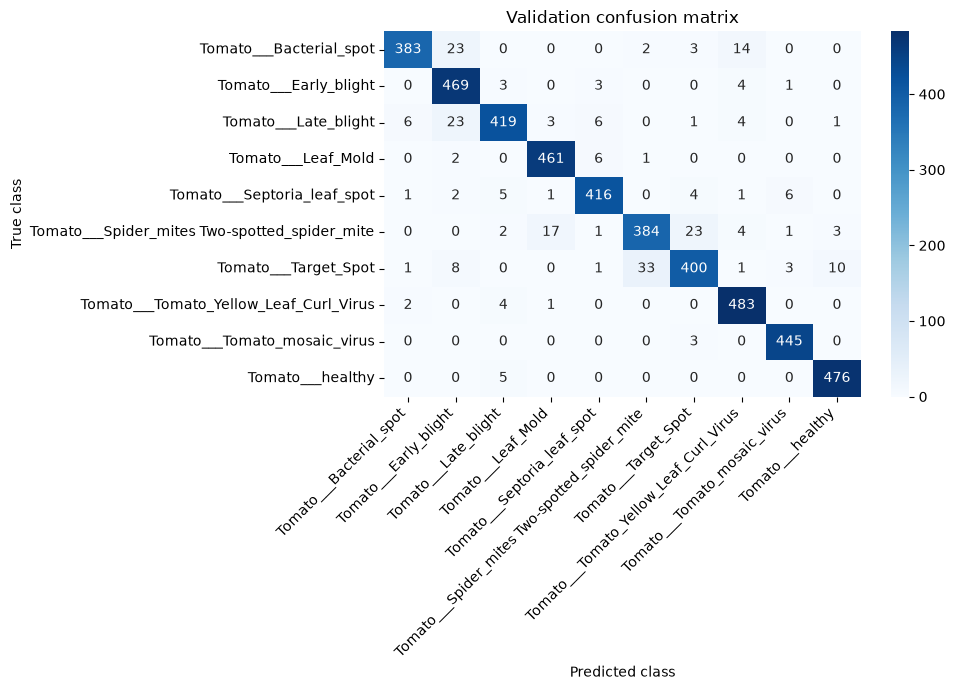

In [26]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(max(8, NUM_CLASSES), max(6, NUM_CLASSES * 0.7)))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.title("Validation confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 26. Per-class precision, recall, and F1

In [27]:
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)

per_class_df = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
})
display(per_class_df.round(4))

,class_name,precision,recall,f1_score,support
0,Tomato___Bacterial_spot,0.9746,0.9012,0.9364,425
1,Tomato___Early_blight,0.8899,0.9771,0.9315,480
2,Tomato___Late_blight,0.9566,0.9050,0.9301,463
3,Tomato___Leaf_Mold,0.9545,0.9809,0.9675,470
4,Tomato___Septoria_leaf_spot,0.9607,0.9541,0.9574,436
5,Tomato___Spider_mites Two-spotted_spider_mite,0.9143,0.8828,0.8982,435
6,Tomato___Target_Spot,0.9217,0.8753,0.8979,457
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,0.9452,0.9857,0.9650,490
8,Tomato___Tomato_mosaic_virus,0.9759,0.9933,0.9845,448
9,Tomato___healthy,0.9714,0.9896,0.9804,481


## 27. Visualize sample predictions

Found 4585 files belonging to 10 classes.


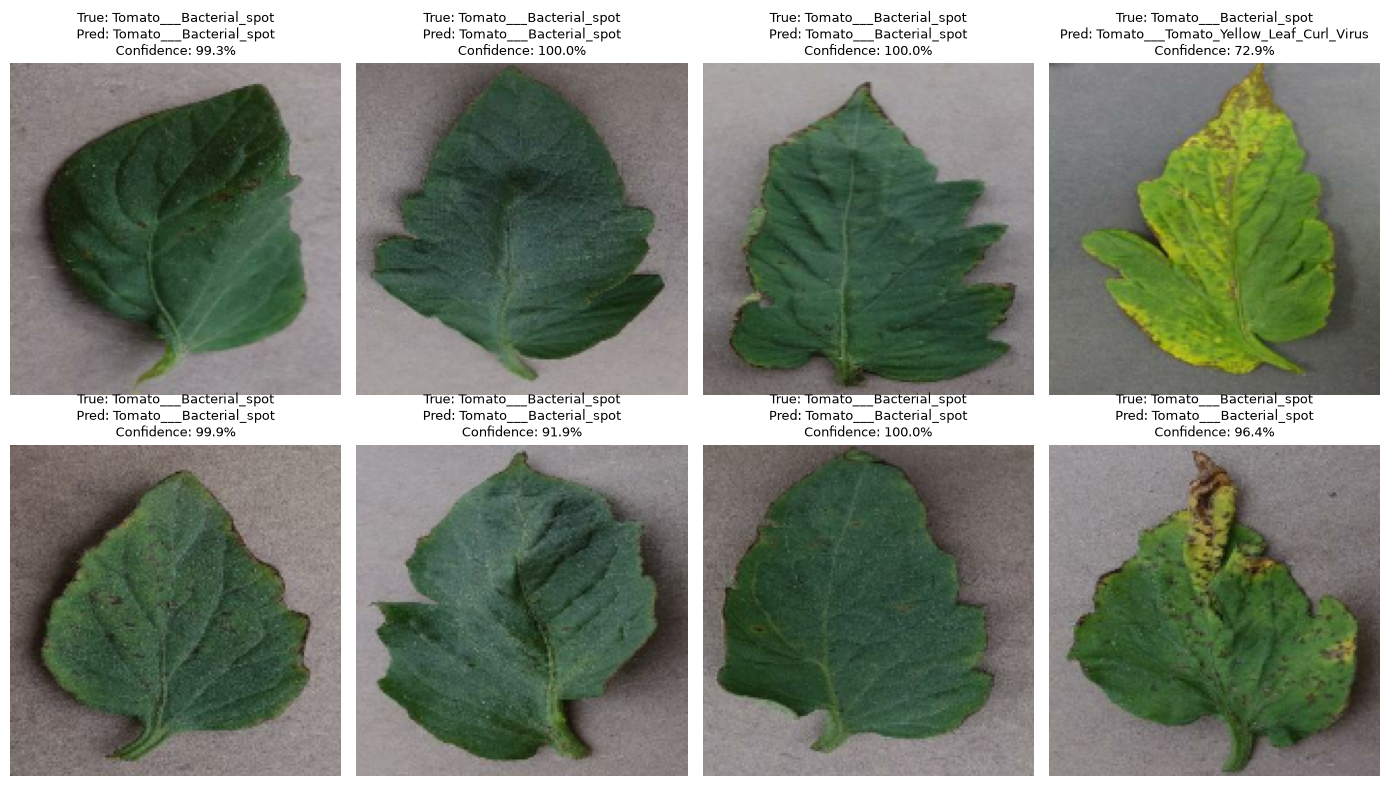

In [28]:
display_ds = keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

sample_images, sample_labels = next(iter(display_ds))
sample_probabilities = model.predict(sample_images, verbose=0)
sample_predictions = np.argmax(sample_probabilities, axis=1)

plt.figure(figsize=(14, 8))
for i in range(min(8, len(sample_labels))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))

    true_name = CLASS_NAMES[int(sample_labels[i].numpy())]
    pred_name = CLASS_NAMES[int(sample_predictions[i])]
    confidence = float(np.max(sample_probabilities[i]))

    plt.title(
        f"True: {true_name}\nPred: {pred_name}\nConfidence: {confidence:.1%}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 28. Save model, class mapping, history, and metrics

In [29]:
final_model_path = OUTPUT_DIR / "tomato_disease_cnn_final.keras"
class_mapping_path = OUTPUT_DIR / "class_mapping.json"
history_path = OUTPUT_DIR / "training_history.csv"
metrics_path = OUTPUT_DIR / "validation_metrics.json"

model.save(final_model_path)

class_mapping = {str(i): name for i, name in enumerate(CLASS_NAMES)}
with open(class_mapping_path, "w", encoding="utf-8") as f:
    json.dump(class_mapping, f, indent=4)

history_df.to_csv(history_path, index=False)

metrics = {
    "validation_loss": float(val_loss),
    "validation_accuracy": float(val_accuracy),
    "training_time_seconds": float(training_seconds),
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history.history["loss"]),
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

print("Saved model:", final_model_path.resolve())
print("Saved class mapping:", class_mapping_path.resolve())
print("Saved history:", history_path.resolve())
print("Saved metrics:", metrics_path.resolve())

Saved model: D:\NN\Tomato Plant Diseases Augmented\tomato_cnn_outputs\tomato_disease_cnn_final.keras
Saved class mapping: D:\NN\Tomato Plant Diseases Augmented\tomato_cnn_outputs\class_mapping.json
Saved history: D:\NN\Tomato Plant Diseases Augmented\tomato_cnn_outputs\training_history.csv
Saved metrics: D:\NN\Tomato Plant Diseases Augmented\tomato_cnn_outputs\validation_metrics.json


## 29. Reload model and test one prediction

In [30]:
reloaded_model = keras.models.load_model(final_model_path)

for images, labels in display_ds.take(1):
    image_batch = images[:1]
    true_index = int(labels[0].numpy())
    probabilities = reloaded_model.predict(image_batch, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    print("Actual class:", CLASS_NAMES[true_index])
    print("Predicted class:", CLASS_NAMES[predicted_index])
    print("Predicted confidence:", f"{probabilities[predicted_index]:.2%}")

Actual class: Tomato___Bacterial_spot
Predicted class: Tomato___Bacterial_spot
Predicted confidence: 99.27%


## 30. Grad-CAM helper
Grad-CAM highlights image regions associated with a class score. It is an explanatory visualization, not causal proof.

In [31]:
def make_gradcam_heatmap(image_batch, trained_model, conv_layer_name="last_conv"):
    grad_model = keras.Model(
        inputs=trained_model.inputs,
        outputs=[
            trained_model.get_layer(conv_layer_name).output,
            trained_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image_batch, training=False)
        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_gradients, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + keras.backend.epsilon())

    return heatmap.numpy(), int(class_index.numpy()), predictions[0].numpy()

## 31. Generate a Grad-CAM visualization

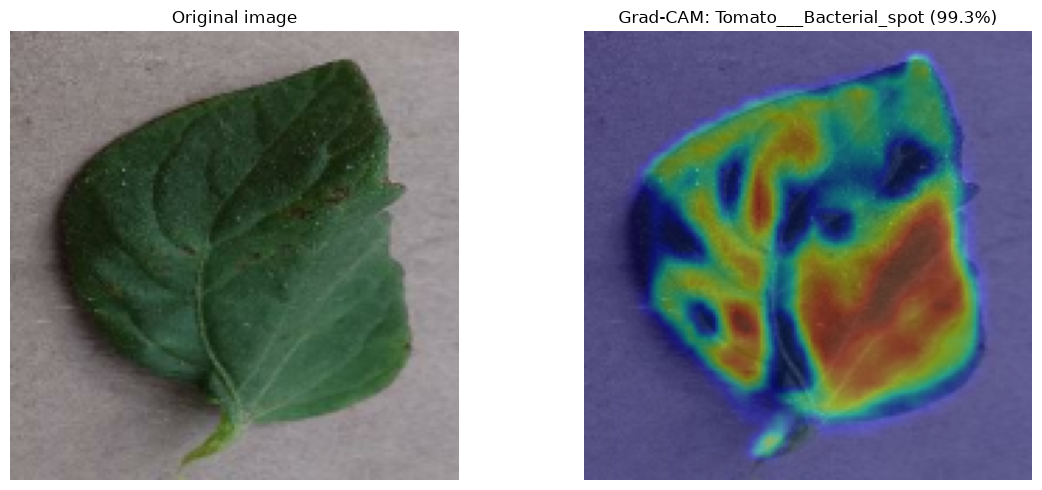

In [32]:
heatmap, predicted_index, prediction_scores = make_gradcam_heatmap(
    sample_images[:1],
    model,
    conv_layer_name="last_conv"
)

original_image = sample_images[0].numpy().astype("uint8")
resized_heatmap = tf.image.resize(
    heatmap[..., np.newaxis], IMG_SIZE
).numpy().squeeze()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(resized_heatmap, cmap="jet", alpha=0.4)
plt.title(
    f"Grad-CAM: {CLASS_NAMES[predicted_index]} "
    f"({prediction_scores[predicted_index]:.1%})"
)
plt.axis("off")

plt.tight_layout()
plt.show()

## 32. Save a compact experiment record

In [40]:
experiment_record = {
    "experiment": "CNN_Baseline_160px_CPU",
    "tensorflow_version": tf.__version__,
    "execution": "CPU only",
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs_completed": len(history.history["loss"]),
    "num_classes": NUM_CLASSES,
    "validation_accuracy": float(val_accuracy),
    "validation_loss": float(val_loss),
    "training_time_seconds": float(training_seconds)
}
display(pd.Series(experiment_record))

experiment               CNN_Baseline_160px_CPU
tensorflow_version                       2.21.0
execution                              CPU only
image_size                           [160, 160]
batch_size                                   16
learning_rate                             0.001
epochs_completed                             20
num_classes                                  10
validation_accuracy                    0.945692
validation_loss                        0.163664
training_time_seconds              30286.519035
dtype: object

PREPARE STREAMLIT MODEL FILES

In [41]:
# ============================================================
# PREPARE STREAMLIT MODEL FILES
# ============================================================

from pathlib import Path
import json

# Create application directory
APP_DIR = Path("Tomato_Disease_Streamlit")
MODEL_DIR = APP_DIR / "tomato_cnn_outputs"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model
STREAMLIT_MODEL_PATH = MODEL_DIR / "tomato_disease_cnn_final.keras"

model.save(STREAMLIT_MODEL_PATH)

# Save class mapping
class_mapping = {
    str(index): class_name
    for index, class_name in enumerate(CLASS_NAMES)
}

STREAMLIT_MAPPING_PATH = MODEL_DIR / "class_mapping.json"

with open(STREAMLIT_MAPPING_PATH, "w", encoding="utf-8") as file:
    json.dump(class_mapping, file, indent=4)

print("Streamlit model files prepared.")
print("Model:", STREAMLIT_MODEL_PATH.resolve())
print("Class mapping:", STREAMLIT_MAPPING_PATH.resolve())

Streamlit model files prepared.
Model: D:\NN\Tomato Plant Diseases Augmented\Tomato_Disease_Streamlit\tomato_cnn_outputs\tomato_disease_cnn_final.keras
Class mapping: D:\NN\Tomato Plant Diseases Augmented\Tomato_Disease_Streamlit\tomato_cnn_outputs\class_mapping.json


# ============================================================
# STREAMLIT APPLICATION
# TOMATO PLANT DISEASE RECOGNITION
# ============================================================

In [42]:
# ============================================================
# STREAMLIT APPLICATION
# TOMATO PLANT DISEASE RECOGNITION
# ============================================================

streamlit_code = r'''
from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd
import streamlit as st
import tensorflow as tf

from PIL import Image


# ============================================================
# 1. APPLICATION CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Tomato Disease Recognition",
    page_icon="🍅",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent

MODEL_PATH = (
    BASE_DIR /
    "tomato_cnn_outputs" /
    "tomato_disease_cnn_final.keras"
)

MAPPING_PATH = (
    BASE_DIR /
    "tomato_cnn_outputs" /
    "class_mapping.json"
)

IMAGE_SIZE = (160, 160)


# ============================================================
# 2. LOAD TRAINED MODEL
# ============================================================

@st.cache_resource
def load_model_and_classes():

    model = tf.keras.models.load_model(
        MODEL_PATH
    )

    with open(MAPPING_PATH, "r", encoding="utf-8") as file:
        mapping = json.load(file)

    classes = [
        mapping[key]
        for key in sorted(mapping.keys(), key=int)
    ]

    if model.output_shape[-1] != len(classes):
        raise ValueError(
            "Model output and class mapping do not match."
        )

    if tuple(model.input_shape[1:]) != (160, 160, 3):
        raise ValueError(
            f"Expected 160x160 RGB input, got {model.input_shape}"
        )

    return model, classes


# ============================================================
# 3. IMAGE PREPROCESSING
# ============================================================

def preprocess_image(uploaded_file):

    image = Image.open(
        uploaded_file
    ).convert("RGB")

    resized_image = image.resize(
        IMAGE_SIZE
    )

    image_array = np.asarray(
        resized_image,
        dtype=np.float32
    )

    # The trained CNN already contains Rescaling(1./255).
    # Do not normalize the image a second time.

    image_batch = np.expand_dims(
        image_array,
        axis=0
    )

    return image, image_batch


# ============================================================
# 4. GENERATE CLASSIFICATION REPORT
# ============================================================

def generate_report(
    filename,
    predicted_class,
    confidence,
    probabilities,
    class_names
):

    timestamp = datetime.now().astimezone().strftime(
        "%Y-%m-%d %H:%M:%S %Z"
    )

    scores = pd.DataFrame({
        "Class": class_names,
        "Probability (%)": probabilities * 100
    })

    scores = scores.sort_values(
        "Probability (%)",
        ascending=False
    )

    report = [
        "TOMATO PLANT DISEASE CLASSIFICATION REPORT",
        "=" * 48,
        f"Image: {filename}",
        f"Date: {timestamp}",
        f"Predicted class: {predicted_class}",
        f"Top model score: {confidence:.2%}",
        "",
        "CLASS SCORES",
        "-" * 48
    ]

    for _, row in scores.iterrows():

        report.append(
            f"{row['Class']}: "
            f"{row['Probability (%)']:.2f}%"
        )

    report.extend([
        "",
        "INTERPRETATION",
        "-" * 48,
        "This is a CNN model prediction, not a verified diagnosis.",
        "Softmax scores are not necessarily calibrated probabilities.",
        "Image quality and dataset differences may affect predictions.",
        "Consult a qualified agricultural specialist for important decisions."
    ])

    return timestamp, scores, "\n".join(report)


# ============================================================
# 5. APPLICATION HEADER
# ============================================================

st.title(
    "🍅 Tomato Plant Disease Recognition"
)

st.write(
    "Upload a tomato leaf image to identify its "
    "predicted disease class using a trained CNN."
)

st.sidebar.title("Model Information")

st.sidebar.write("Architecture: CNN")
st.sidebar.write("Framework: TensorFlow / Keras")
st.sidebar.write("Image size: 160 × 160")
st.sidebar.write("Execution: CPU compatible")


# ============================================================
# 6. LOAD MODEL AND CLASS LABELS
# ============================================================

try:

    model, class_names = load_model_and_classes()

    st.sidebar.success(
        "Model loaded successfully"
    )

except Exception as error:

    st.error(
        f"Model loading failed: {error}"
    )

    st.stop()


# ============================================================
# 7. IMAGE UPLOAD
# ============================================================

uploaded_file = st.file_uploader(
    "Upload a tomato leaf image",
    type=["jpg", "jpeg", "png", "bmp"]
)


# ============================================================
# 8. IMAGE RECOGNITION
# ============================================================

if uploaded_file is not None:

    try:

        original_image, image_batch = preprocess_image(
            uploaded_file
        )

        with st.spinner("Analyzing image..."):

            predictions = model.predict(
                image_batch,
                verbose=0
            )[0]

        predicted_index = int(
            np.argmax(predictions)
        )

        predicted_class = class_names[
            predicted_index
        ]

        confidence = float(
            predictions[predicted_index]
        )

        # ----------------------------------------------------
        # DISPLAY IMAGE AND RESULT
        # ----------------------------------------------------

        col1, col2 = st.columns(2)

        with col1:

            st.subheader("Uploaded Image")

            st.image(
                original_image,
                use_container_width=True
            )

        with col2:

            st.subheader("Recognition Result")

            st.metric(
                "Predicted Class",
                predicted_class
            )

            st.metric(
                "Top Model Score",
                f"{confidence:.2%}"
            )

            if confidence < 0.60:

                st.warning(
                    "The top score is relatively low. "
                    "Interpret this prediction cautiously."
                )

            else:

                st.info(
                    "This is the model's top prediction, "
                    "not a guarantee of correctness."
                )

        # ----------------------------------------------------
        # CLASS SCORES
        # ----------------------------------------------------

        st.divider()

        st.subheader(
            "Classification Scores"
        )

        timestamp, scores_df, report_text = generate_report(
            uploaded_file.name,
            predicted_class,
            confidence,
            predictions,
            class_names
        )

        st.bar_chart(
            scores_df.set_index("Class")
        )

        st.dataframe(
            scores_df,
            use_container_width=True,
            hide_index=True
        )

        # ----------------------------------------------------
        # CLASSIFICATION REPORT
        # ----------------------------------------------------

        st.divider()

        st.subheader(
            "Classification Report"
        )

        st.caption(
            f"Report generated: {timestamp}"
        )

        st.text_area(
            "Report Preview",
            report_text,
            height=300
        )

        # ----------------------------------------------------
        # DOWNLOAD REPORT
        # ----------------------------------------------------

        filename = Path(
            uploaded_file.name
        ).stem.replace(" ", "_")

        st.download_button(
            label="Download Classification Report",
            data=report_text,
            file_name=f"{filename}_report.txt",
            mime="text/plain"
        )

        st.download_button(
            label="Download Class Scores CSV",
            data=scores_df.to_csv(index=False),
            file_name=f"{filename}_scores.csv",
            mime="text/csv"
        )

    except Exception as error:

        st.error(
            f"Image processing failed: {error}"
        )

else:

    st.info(
        "Upload an image to start disease recognition."
    )


# ============================================================
# 9. FOOTER
# ============================================================

st.divider()

st.caption(
    "Tomato Disease CNN Research Prototype | "
    "TensorFlow and Streamlit"
)

st.caption(
    "This application is intended for research and educational "
    "purposes. Validate the model using independent test data "
    "before real-world agricultural use."
)
'''


# Save app.py
APP_FILE = APP_DIR / "app.py"

with open(APP_FILE, "w", encoding="utf-8") as file:
    file.write(streamlit_code)

print("Streamlit application created:")
print(APP_FILE.resolve())

Streamlit application created:
D:\NN\Tomato Plant Diseases Augmented\Tomato_Disease_Streamlit\app.py


In [44]:
# ============================================================
# LAUNCH STREAMLIT
# ============================================================

import subprocess
import sys

subprocess.Popen([
    sys.executable,
    "-m",
    "streamlit",
    "run",
    str(APP_FILE.resolve())
])

print("Streamlit application is starting...")
print("Open the local URL displayed in the terminal.")

Streamlit application is starting...
Open the local URL displayed in the terminal.


## 33. Research interpretation and next experiments

- Confirm that augmented versions of one original image are not distributed across train and validation. The exact-hash check above cannot detect transformed copies.
- Create an independent test set before reporting final generalization performance.
- Examine per-class recall and F1, not accuracy alone.
- Test robustness across plants, cameras, lighting, backgrounds, and image acquisition conditions.
- Compare 160 × 160 and 224 × 224 in a controlled experiment after this baseline works.
- Compare this CNN with transfer learning and more advanced architectures.
- Later investigate probability calibration and uncertainty. Softmax confidence is not automatically a calibrated probability.
- This tomato-leaf exercise is useful computer-vision practice, but does not itself validate a biomedical imaging method.

## Troubleshooting the previous input-shape error

If Keras reports `expected shape=(None, 224, 224, 3), found shape=(None, 160, 160, 3)`:

1. Restart the Jupyter kernel.
2. Run the notebook from the first cell.
3. Search for old `224` input declarations.
4. Keep `IMG_SIZE = (160, 160)` and `INPUT_SHAPE = (160, 160, 3)`.
5. Ensure the augmentation layer is the one defined in Section 13.
6. Confirm the assertions in Section 15 pass before training.

Do not reuse an old model or augmentation layer from a previous kernel session.